<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Accuracy = 91.11%
setosa      precision = 1.00   recall = 1.00
versicolor  precision = 0.82   recall = 0.93
virginica   precision = 0.92   recall = 0.80

New sample [6.0, 3.0, 4.8, 1.8] -> virginica


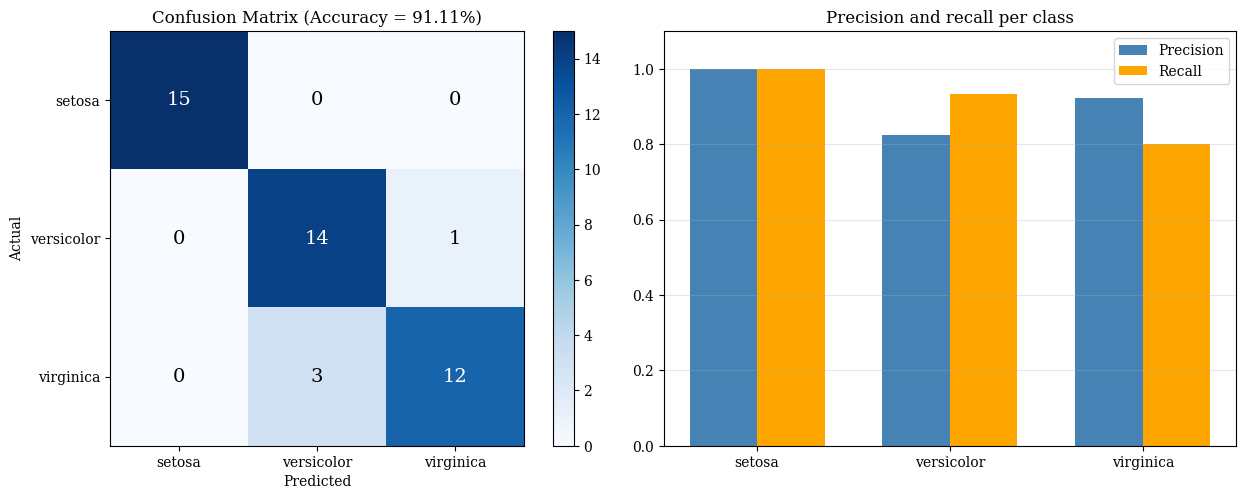

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
names = iris.target_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

class GaussianNB:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = {c: np.mean(y == c) for c in self.classes}           # P(class)
        self.mean  = {c: X[y == c].mean(axis=0) for c in self.classes}    # feature means
        self.var   = {c: X[y == c].var(axis=0) + 1e-9 for c in self.classes}

    def log_posterior(self, x, c):
        log_likelihood = -0.5 * np.sum(np.log(2 * np.pi * self.var[c])) \
                         -0.5 * np.sum((x - self.mean[c]) ** 2 / self.var[c])
        return np.log(self.prior[c]) + log_likelihood

    def predict(self, X):
        return np.array([self.classes[np.argmax([self.log_posterior(x, c) for c in self.classes])]
                         for x in X])

model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Confusion matrix (rows = actual, columns = predicted)
cm = np.zeros((3, 3), dtype=int)
for t, p in zip(y_test, y_pred):
    cm[t, p] += 1
accuracy = np.trace(cm) / cm.sum()

print("Confusion Matrix:\n", cm)
print(f"\nAccuracy = {accuracy*100:.2f}%")
precision = np.diag(cm) / cm.sum(axis=0)
recall = np.diag(cm) / cm.sum(axis=1)
for i, n in enumerate(names):
    print(f"{n:11s} precision = {precision[i]:.2f}   recall = {recall[i]:.2f}")

sample = [6.0, 3.0, 4.8, 1.8]
print("\nNew sample", sample, "->", names[model.predict(np.array([sample]))[0]])

# ---- Graphs
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(names)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(names)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
ax[0].set_title(f"Confusion Matrix (Accuracy = {accuracy*100:.2f}%)")
plt.colorbar(im, ax=ax[0])

w = 0.35; pos = np.arange(3)
ax[1].bar(pos - w/2, precision, w, label="Precision", color="steelblue")
ax[1].bar(pos + w/2, recall, w, label="Recall", color="orange")
ax[1].set_xticks(pos); ax[1].set_xticklabels(names); ax[1].set_ylim(0, 1.1)
ax[1].set_title("Precision and recall per class"); ax[1].legend(); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()